# Análise Exploratória de Dados - Seoul Bike Sharing Demand
**Objetivo:** Contextualizar o domínio do problema, investigar dependências entre variáveis climáticas, temporais e de demanda por bicicletas, fundamentar os limiares de discretização e extrair frequências empíricas para apoiar a construção manual da Rede Bayesiana.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style="whitegrid")

# Carregamento tratando a codificação latin1 do dataset original
caminho_csv = '../dataset/SeoulBikeData.csv'
df_raw = pd.read_csv(caminho_csv, encoding='latin1')

# Padronização dos nomes das colunas para evitar problemas com caracteres especiais
mapa_colunas = {}
for col in df_raw.columns:
    if 'Date' in col: mapa_colunas[col] = 'date'
    elif 'Rented' in col: mapa_colunas[col] = 'rented_bike_count'
    elif 'Hour' in col: mapa_colunas[col] = 'hour'
    elif col.startswith('Temperature'): mapa_colunas[col] = 'temperature'
    elif 'Humidity' in col: mapa_colunas[col] = 'humidity'
    elif 'Wind' in col: mapa_colunas[col] = 'wind_speed'
    elif 'Visibility' in col: mapa_colunas[col] = 'visibility'
    elif 'Dew' in col: mapa_colunas[col] = 'dew_point'
    elif 'Solar' in col: mapa_colunas[col] = 'solar_radiation'
    elif 'Rainfall' in col: mapa_colunas[col] = 'rainfall'
    elif 'Snowfall' in col: mapa_colunas[col] = 'snowfall'
    elif 'Seasons' in col: mapa_colunas[col] = 'seasons'
    elif 'Holiday' in col: mapa_colunas[col] = 'holiday'
    elif 'Functioning' in col: mapa_colunas[col] = 'functioning_day'

df = df_raw.rename(columns=mapa_colunas).copy()

print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("\nValores nulos por coluna:")
print(df.isnull().sum())
print("\nTipos de dados e primeiras linhas:")
display(df.head())

Dimensões do dataset: 8760 linhas x 14 colunas

Valores nulos por coluna:
date                 0
rented_bike_count    0
hour                 0
temperature          0
humidity             0
wind_speed           0
visibility           0
dew_point            0
solar_radiation      0
rainfall             0
snowfall             0
seasons              0
holiday              0
functioning_day      0
dtype: int64

Tipos de dados e primeiras linhas:


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [2]:
# Estatísticas descritivas detalhadas com percentis para a discretização
percentis = [0.1, 0.25, 0.33, 0.5, 0.66, 0.75, 0.9]
stats_num = df.describe(percentiles=percentis).T
display(stats_num[['count', 'mean', 'std', 'min', '25%', '33%', '50%', '66%', '75%', 'max']])

print("\nDistribuição das variáveis categóricas originais:")
for col_cat in ['seasons', 'holiday', 'functioning_day']:
    print(f"\n--- {col_cat.upper()} ---")
    print(df[col_cat].value_counts(normalize=True).round(4))

# Verificação de casos especiais: chuva, neve e dias inativos
print("\nProporção de registros com Chuva (rainfall > 0):", (df['rainfall'] > 0).mean().round(4))
print("Proporção de registros com Neve (snowfall > 0):", (df['snowfall'] > 0).mean().round(4))
print("Demanda máxima quando functioning_day == 'No':", df.loc[df['functioning_day'] == 'No', 'rented_bike_count'].max())

,count,mean,std,min,25%,33%,50%,66%,75%,max
rented_bike_count,8760.0,704.602055,644.997468,0.0,191.00,262.0,504.50,842.94,1065.25,3556.00
hour,8760.0,11.500000,6.922582,0.0,5.75,7.0,11.50,15.00,17.25,23.00
temperature,8760.0,12.882922,11.944825,-17.8,3.50,6.7,13.70,19.70,22.50,39.40
humidity,8760.0,58.226256,20.362413,0.0,42.00,47.0,57.00,68.00,74.00,98.00
wind_speed,8760.0,1.724909,1.036300,0.0,0.90,1.1,1.50,2.00,2.30,7.40
visibility,8760.0,1436.825799,608.298712,27.0,940.00,1191.0,1698.00,1956.00,2000.00,2000.00
dew_point,8760.0,4.073813,13.060369,-30.6,-4.70,-1.2,5.10,11.20,14.80,27.20
solar_radiation,8760.0,0.569111,0.868746,0.0,0.00,0.0,0.01,0.46,0.93,3.52
rainfall,8760.0,0.148687,1.128193,0.0,0.00,0.0,0.00,0.00,0.00,35.00
snowfall,8760.0,0.075068,0.436746,0.0,0.00,0.0,0.00,0.00,0.00,8.80



Distribuição das variáveis categóricas originais:

--- SEASONS ---
seasons
Spring    0.2521
Summer    0.2521
Autumn    0.2493
Winter    0.2466
Name: proportion, dtype: float64

--- HOLIDAY ---
holiday
No Holiday    0.9507
Holiday       0.0493
Name: proportion, dtype: float64

--- FUNCTIONING_DAY ---
functioning_day
Yes    0.9663
No     0.0337
Name: proportion, dtype: float64

Proporção de registros com Chuva (rainfall > 0): 0.0603
Proporção de registros com Neve (snowfall > 0): 0.0506
Demanda máxima quando functioning_day == 'No': 0


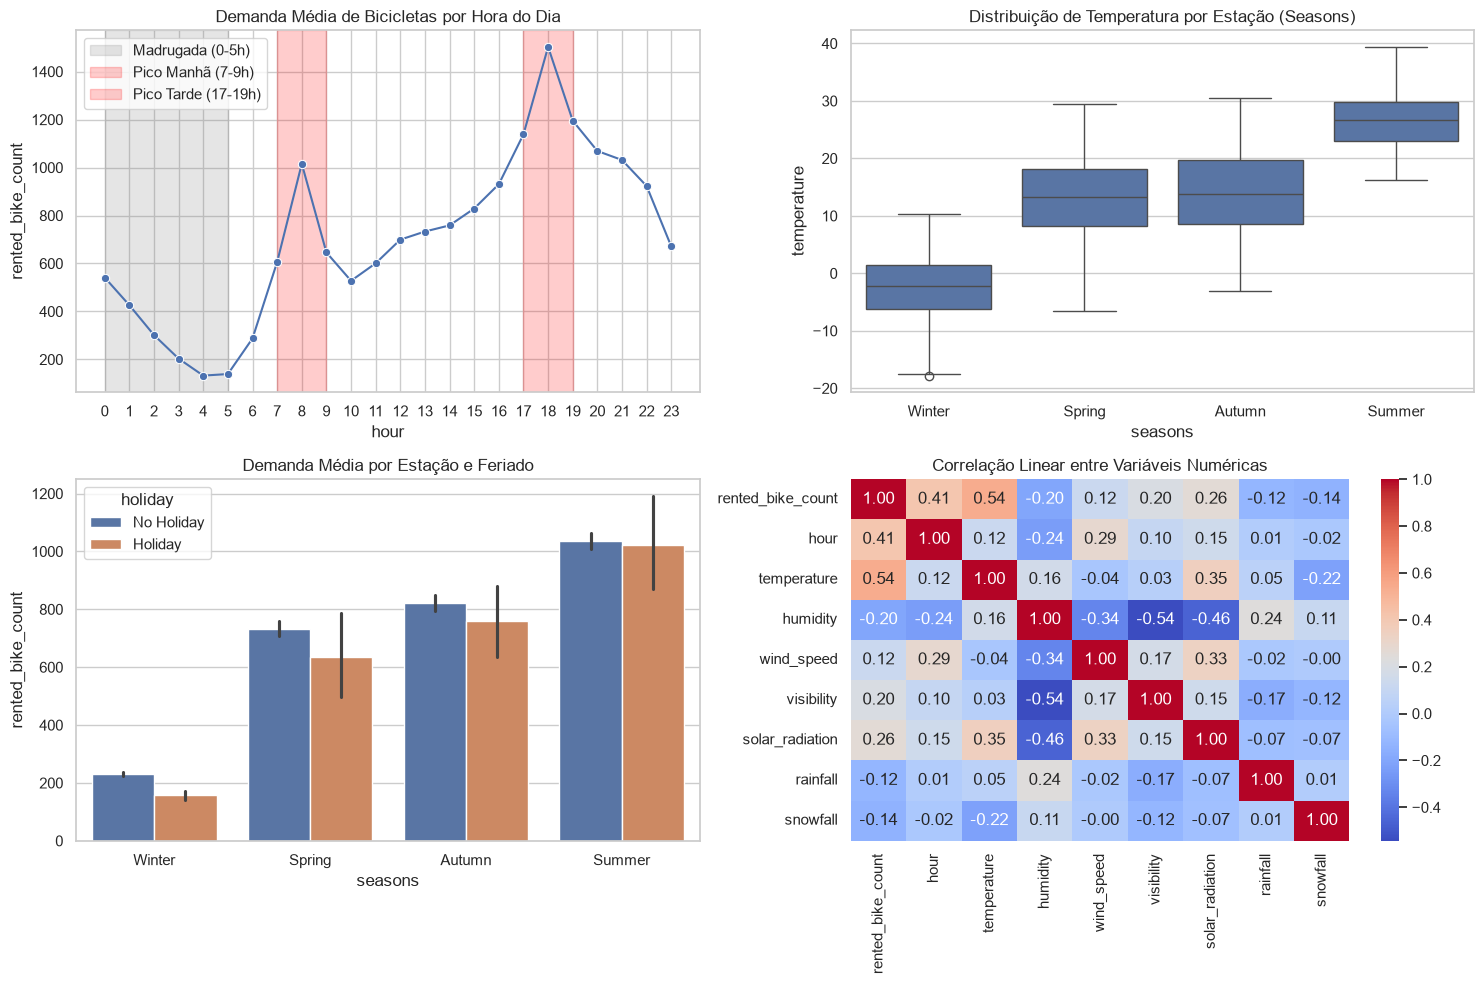

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Demanda média por Hora do Dia
sns.lineplot(data=df, x='hour', y='rented_bike_count', marker='o', ax=axes[0, 0], errorbar=None)
axes[0, 0].axvspan(0, 5, color='gray', alpha=0.2, label='Madrugada (0-5h)')
axes[0, 0].axvspan(7, 9, color='red', alpha=0.2, label='Pico Manhã (7-9h)')
axes[0, 0].axvspan(17, 19, color='red', alpha=0.2, label='Pico Tarde (17-19h)')
axes[0, 0].set_title('Demanda Média de Bicicletas por Hora do Dia')
axes[0, 0].set_xticks(range(0, 24))
axes[0, 0].legend()

# Temperatura por Estação do Ano
sns.boxplot(data=df, x='seasons', y='temperature', order=['Winter', 'Spring', 'Autumn', 'Summer'], ax=axes[0, 1])
axes[0, 1].set_title('Distribuição de Temperatura por Estação (Seasons)')

# Demanda por Estação e Feriado
sns.barplot(data=df, x='seasons', y='rented_bike_count', hue='holiday', order=['Winter', 'Spring', 'Autumn', 'Summer'], ax=axes[1, 0])
axes[1, 0].set_title('Demanda Média por Estação e Feriado')

# Matriz de Correlação de Pearson entre variáveis numéricas
cols_corr = ['rented_bike_count', 'hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'solar_radiation', 'rainfall', 'snowfall']
sns.heatmap(df[cols_corr].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title('Correlação Linear entre Variáveis Numéricas')

plt.tight_layout()
plt.show()

## Fundamentação das Variáveis Discretas e Topologia da Rede
Para evitar explosão combinatória nas Tabelas de Probabilidade Condicional (CPTs) e respeitar a direção causal física:
1. **`estacao`** (`Inverno`, `Meia_Estacao`, `Verao`): *Spring* e *Autumn* apresentam perfis térmicos e de demanda semelhantes, sendo unificados em `Meia_Estacao`.
2. **`horario`** (`Madrugada`, `Comercial`, `Pico`): Baseado nos dois picos claros de deslocamento pendular (7h-9h e 17h-19h) e na baixa atividade entre 0h-5h.
3. **`feriado`** (`Nao`, `Sim`) e **`dia_ativo`** (`Nao`, `Sim`): Variáveis de calendário e operação do sistema.
4. **Camada Meteorológica Primária (`radiacao_solar`, `umidade`, `vento`)**: Influenciadas diretamente por `estacao` e `horario`.
5. **Camada Meteorológica Secundária (`temperatura`, `precipitacao`, `visibilidade`)**:
   - `temperatura` depende de `estacao` e `radiacao_solar`.
   - `precipitacao` (`Nenhuma`, `Chuva`, `Neve`) depende de `umidade` e `temperatura` (neve requer temperaturas baixas).
   - `visibilidade` (`Baixa`, `Alta`) depende de `precipitacao` e `umidade` (neblina/chuva).
6. **Variável Intermediária (`conforto_climatico`)**: Sintetiza `temperatura`, `precipitacao` e `vento` em (`Desfavoravel`, `Moderado`, `Favoravel`), mantendo a tabela de **`demanda`** esparsa e interpretável.

In [ ]:
df_disc = pd.DataFrame(index=df.index)

# Nós Raízes (Calendário, Relógio e Operação)
df_disc['estacao'] = df['seasons'].map({
    'Winter': 'Inverno',
    'Summer': 'Verao',
    'Spring': 'Meia_Estacao',
    'Autumn': 'Meia_Estacao'
})

def classificar_horario(h):
    if 0 <= h <= 5:
        return 'Madrugada'
    elif (7 <= h <= 9) or (17 <= h <= 19):
        return 'Pico'
    else:
        return 'Comercial'

df_disc['horario'] = df['hour'].apply(classificar_horario)
df_disc['feriado'] = df['holiday'].map({'No Holiday': 'Nao', 'Holiday': 'Sim'})
df_disc['dia_ativo'] = df['functioning_day'].map({'No': 'Nao', 'Yes': 'Sim'})

# Camada Meteorológica 1
# Radiação Solar: 0 (noite/sem sol) = Baixa; até 1.0 = Moderada; > 1.0 = Alta
df_disc['radiacao_solar'] = pd.cut(
    df['solar_radiation'],
    bins=[-np.inf, 0.05, 1.0, np.inf],
    labels=['Baixa', 'Moderada', 'Alta']
).astype(str)

# Umidade: < 45% = Baixa; 45% a 75% = Moderada; > 75% = Alta
df_disc['umidade'] = pd.cut(
    df['humidity'],
    bins=[-np.inf, 45, 75, np.inf],
    labels=['Baixa', 'Moderada', 'Alta']
).astype(str)

# Vento: < 2.0 m/s = Fraco; >= 2.0 m/s = Forte
df_disc['vento'] = pd.cut(
    df['wind_speed'],
    bins=[-np.inf, 2.0, np.inf],
    labels=['Fraco', 'Forte']
).astype(str)

# Camada Meteorológica 2
# Temperatura: < 5°C = Baixa; 5°C a 22°C = Amena; > 22°C = Alta
df_disc['temperatura'] = pd.cut(
    df['temperature'],
    bins=[-np.inf, 5.0, 22.0, np.inf],
    labels=['Baixa', 'Amena', 'Alta']
).astype(str)

# Precipitação: combina Rainfall e Snowfall
def classificar_precipitacao(row):
    if row['snowfall'] > 0:
        return 'Neve'
    elif row['rainfall'] > 0:
        return 'Chuva'
    else:
        return 'Nenhuma'

df_disc['precipitacao'] = df.apply(classificar_precipitacao, axis=1)

# Visibilidade: < 1000 (10m) = Baixa; >= 1000 = Alta
df_disc['visibilidade'] = pd.cut(
    df['visibility'],
    bins=[-np.inf, 1000, np.inf],
    labels=['Baixa', 'Alta']
).astype(str)

# Variável Intermediária de Domínio: Conforto Climático para o Ciclista
def classificar_conforto(row):
    if row['precipitacao'] in ['Chuva', 'Neve']:
        return 'Desfavoravel'
    if row['temperatura'] == 'Baixa' and row['vento'] == 'Forte':
        return 'Desfavoravel'
    if row['temperatura'] == 'Amena' and row['vento'] == 'Fraco':
        return 'Favoravel'
    if row['temperatura'] == 'Alta' and row['vento'] == 'Fraco':
        return 'Favoravel'
    return 'Moderado'

df_disc['conforto_climatico'] = df_disc.apply(classificar_conforto, axis=1)

# Variável Alvo: Demanda de Bicicletas (< 250 = Baixa; 250 a 850 = Moderada; > 850 = Alta)
df_disc['demanda'] = pd.cut(
    df['rented_bike_count'],
    bins=[-np.inf, 250, 850, np.inf],
    labels=['Baixa', 'Moderada', 'Alta']
).astype(str)

print("Contagem e proporção de cada variável discretizada:\n")
for col in df_disc.columns:
    prop = df_disc[col].value_counts(normalize=True).round(4).to_dict()
    print(f"{col:20s} -> {prop}")

Contagem e proporção de cada variável discretizada:

estacao              -> {'Meia_Estacao': 0.5014, 'Verao': 0.2521, 'Inverno': 0.2466}
horario              -> {'Comercial': 0.5, 'Madrugada': 0.25, 'Pico': 0.25}
feriado              -> {'Nao': 0.9507, 'Sim': 0.0493}
dia_ativo            -> {'Sim': 0.9663, 'Nao': 0.0337}
radiacao_solar       -> {'Baixa': 0.5342, 'Alta': 0.2369, 'Moderada': 0.2289}
umidade              -> {'Moderada': 0.4647, 'Baixa': 0.3026, 'Alta': 0.2326}
vento                -> {'Fraco': 0.6758, 'Forte': 0.3242}
temperatura          -> {'Amena': 0.4502, 'Baixa': 0.2874, 'Alta': 0.2623}
precipitacao         -> {'Nenhuma': 0.8924, 'Chuva': 0.0571, 'Neve': 0.0506}
visibilidade         -> {'Alta': 0.7282, 'Baixa': 0.2718}
conforto_climatico   -> {'Favoravel': 0.4517, 'Moderado': 0.3567, 'Desfavoravel': 0.1916}
demanda              -> {'Moderada': 0.3458, 'Alta': 0.3363, 'Baixa': 0.3179}


In [5]:
# Definição da estrutura proposta (Variável: Lista de Pais)
estrutura_dag = {
    'estacao': [],
    'horario': [],
    'feriado': [],
    'dia_ativo': [],
    'radiacao_solar': ['estacao', 'horario'],
    'umidade': ['estacao', 'horario'],
    'vento': ['estacao', 'horario'],
    'temperatura': ['estacao', 'radiacao_solar'],
    'precipitacao': ['umidade', 'temperatura'],
    'visibilidade': ['precipitacao', 'umidade'],
    'conforto_climatico': ['temperatura', 'precipitacao', 'vento'],
    'demanda': ['conforto_climatico', 'horario', 'feriado', 'dia_ativo']
}

Ordem_estados = {
    'estacao': ['Inverno', 'Meia_Estacao', 'Verao'],
    'horario': ['Madrugada', 'Comercial', 'Pico'],
    'feriado': ['Nao', 'Sim'],
    'dia_ativo': ['Nao', 'Sim'],
    'radiacao_solar': ['Baixa', 'Moderada', 'Alta'],
    'umidade': ['Baixa', 'Moderada', 'Alta'],
    'vento': ['Fraco', 'Forte'],
    'temperatura': ['Baixa', 'Amena', 'Alta'],
    'precipitacao': ['Nenhuma', 'Chuva', 'Neve'],
    'visibilidade': ['Baixa', 'Alta'],
    'conforto_climatico': ['Desfavoravel', 'Moderado', 'Favoravel'],
    'demanda': ['Baixa', 'Moderada', 'Alta']
}

resumo_empirico = {
    "n_registros": len(df),
    "correlacoes_com_demanda": df[['rented_bike_count', 'temperature', 'humidity', 'wind_speed', 'visibility', 'solar_radiation', 'rainfall', 'snowfall']].corr()['rented_bike_count'].round(4).to_dict(),
    "tabelas_empiricas": {}
}

for var, pais in estrutura_dag.items():
    estados_var = Ordem_estados[var]
    if not pais:
        # Probabilidade a priori (nó raiz)
        contagem = df_disc[var].value_counts().reindex(estados_var, fill_value=0)
        probs = (contagem / contagem.sum()).round(4).to_dict()
        resumo_empirico["tabelas_empiricas"][var] = {"pais": [], "distribuicao": probs}
    else:
        # Tabela cruzada condicional com suavização de Laplace apenas para evitar divisão por zero em combinações raras
        ct = pd.crosstab(
            index=df_disc[var],
            columns=[df_disc[p] for p in pais],
            dropna=False
        ).reindex(index=estados_var, fill_value=0)
        
        # Garantir todas as combinações de pais nas colunas
        idx_pais = pd.MultiIndex.from_product([Ordem_estados[p] for p in pais], names=pais) if len(pais) > 1 else pd.Index(Ordem_estados[pais[0]], name=pais[0])
        ct = ct.reindex(columns=idx_pais, fill_value=0)
        
        # Proporção por coluna
        ct_suavizada = ct + 0.5
        ct_norm = (ct_suavizada / ct_suavizada.sum(axis=0)).round(4)
        
        dict_cond = {}
        for col in ct_norm.columns:
            chave_pais = "|".join(col) if isinstance(col, tuple) else str(col)
            dict_cond[chave_pais] = {
                "n_amostras_reais": int(ct[col].sum()),
                "probs": ct_norm[col].to_dict()
            }
        resumo_empirico["tabelas_empiricas"][var] = {"pais": pais, "condicionais": dict_cond}

print(json.dumps(resumo_empirico, indent=2, ensure_ascii=False))

{
  "n_registros": 8760,
  "correlacoes_com_demanda": {
    "rented_bike_count": 1.0,
    "temperature": 0.5386,
    "humidity": -0.1998,
    "wind_speed": 0.1211,
    "visibility": 0.1993,
    "solar_radiation": 0.2618,
    "rainfall": -0.1231,
    "snowfall": -0.1418
  },
  "tabelas_empiricas": {
    "estacao": {
      "pais": [],
      "distribuicao": {
        "Inverno": 0.2466,
        "Meia_Estacao": 0.5014,
        "Verao": 0.2521
      }
    },
    "horario": {
      "pais": [],
      "distribuicao": {
        "Madrugada": 0.25,
        "Comercial": 0.5,
        "Pico": 0.25
      }
    },
    "feriado": {
      "pais": [],
      "distribuicao": {
        "Nao": 0.9507,
        "Sim": 0.0493
      }
    },
    "dia_ativo": {
      "pais": [],
      "distribuicao": {
        "Nao": 0.0337,
        "Sim": 0.9663
      }
    },
    "radiacao_solar": {
      "pais": [
        "estacao",
        "horario"
      ],
      "condicionais": {
        "Inverno|Madrugada": {
          "n_a